In [ ]:
%%time

import json

# Load selected-samples-data 
with open('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/results/allSelected_uniqueSampleIdx_list_LW20230121.json', 'r') as f:
    samples = json.load(f)
print("Total # Biosamples:", len(samples))

# Get unselected samples 
unselected_samples_idxs = [x for x in list(range(0, 620825)) if x not in samples]
print("Unselected Sample Idxs (428,224)", len(unselected_samples_idxs))

with open("428k_unmatched_samplesIdxs_LW20230125.json", "w+") as f:
    json.dump(unselected_samples_idxs, f)

In [4]:
# See unselected samples names 
##############################
import h5py
import re
from collections import Counter

# Open ARCHS4 v2.1 Data
infile = "/home/ajoshi/archs4/data/archs4_gene_human_v2.1.h5"
with h5py.File(infile, 'r') as hdf5_file:
    meta = hdf5_file['meta']
    sample_names = meta['samples']['source_name_ch1'][:]

# Decode source names using list comprehension
sample_names_decoded = [x.decode('UTF-8') for x in sample_names]

# Clean source names using regular expressions
sample_names_cleaned = [re.sub(r'[-/\'\\ _]', '', x) for x in sample_names_decoded]

########################################## ^^^^^ ##########################################
unselected_sample_names = [sample_names_cleaned[i] for i in unselected_samples_idxs]

# Count occurrences of each sample name
sample_name_counts = Counter(unselected_sample_names)

# Print the counts
#print(sample_name_counts)
print("# Unique Unselected Sample Names:", len(sample_name_counts))

# Unique Unselected Sample Names: 37497


# Read Counts Calc

In [5]:
import pickle

pickle_in = open("/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/data_results/archs4_cols_allSamples_readCountSum.pkl", 'rb')
allSample_readCounts = pickle.load(pickle_in)
pickle_in.close()

unselected_sample_readCounts = [allSample_readCounts[i] for i in unselected_samples_idxs]


In [7]:
%%time
import json
import matplotlib.pyplot as plt

# combine the two lists using zip
combined = zip(unselected_sample_names, unselected_sample_readCounts)

# sort the combined list based on the readCounts values in descending order
sorted_combined = sorted(combined, key=lambda x: x[1], reverse=True)

#unzip the sorted combined list
x, y = zip(*sorted_combined)

top_x = x[310412,310512]
top_y = y[310412,310512]

CPU times: user 2.28 s, sys: 32.8 ms, total: 2.31 s
Wall time: 2.31 s


In [27]:
# MODIFICATION - MIDDLE 
x, y = zip(*sorted_combined)

top_x = x[310412:310462]
top_y = y[310412:310462]

# Plot

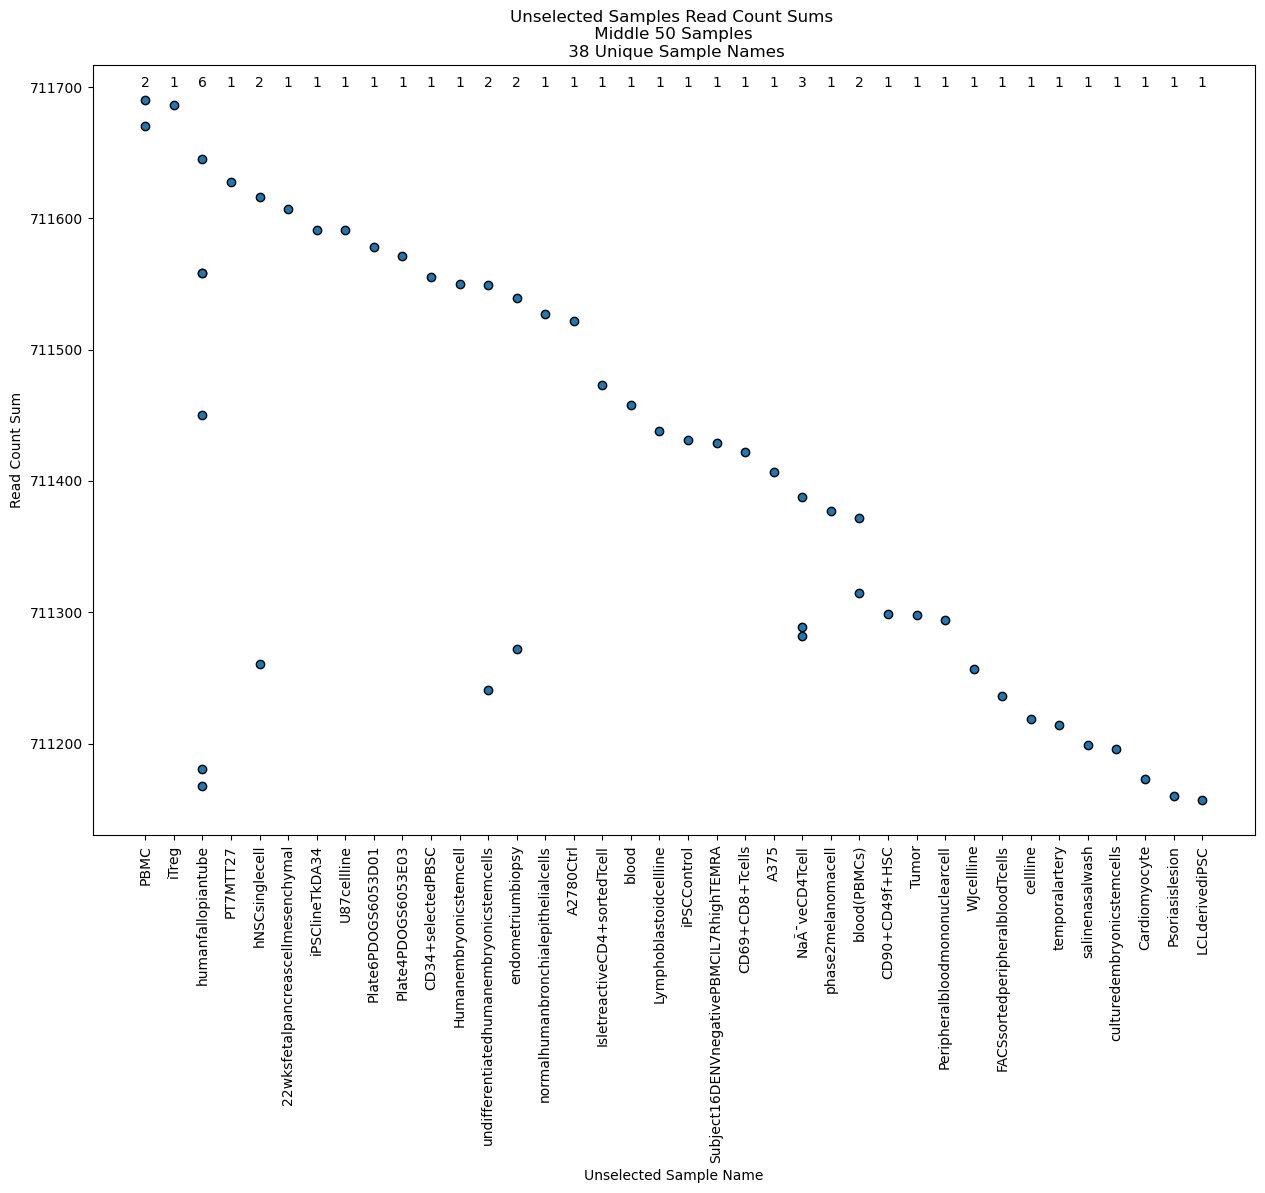

In [36]:
# Create the bar plot
plt.scatter(top_x, top_y, edgecolors='black')
plt.xlabel('Unselected Sample Name')
plt.xticks(rotation=90)
plt.gcf().set_size_inches(15, 10)

# Get the count of dots on each x-value
x_count = {x:top_x.count(x) for x in set(top_x)}

# Add the count to each x-value
for x, count in x_count.items():
    plt.annotate(count, (x, 711700), ha='center')
    
plt.ylabel('Read Count Sum')
plt.title('Unselected Samples Read Count Sums \n Middle 50 Samples \n 38 Unique Sample Names')
#\n Within First 100 Samples, \n 57 Unselected Samples, \n 17 Unique Sample Names in ARCHS4\n
plt.show()

In [35]:
len(list(set(top_x)))

38

# Save Data

In [11]:
import csv

header = ['unselected_archs4_idx', 'sample_name', 'sample_readCount']

with open('428k_unmatched_samples_allData_LW20230125.csv', 'w') as f:
    writer = csv.writer(f)
    writer.writerow(header)
    for i in range(len(unselected_samples_idxs)):
        writer.writerow([unselected_samples_idxs[i], unselected_sample_names[i], unselected_sample_readCounts[i]])


In [14]:
name, sum_ = zip(*sorted_combined)
with open('428k_unmatched_samples_ordered_readCountSums_LW20230125.csv', 'w') as f:
    writer = csv.writer(f)
    writer.writerow(['sample_name', 'sample_readCount'])
    for i in range(len(name)):
        writer.writerow([name[i], sum_[i]])


'TR4PL308GPeripheralbloodJAK2HOMSF3B1HET'

# TEST CODE

In [ ]:

unselected_sample_names = ["Heart", "Eye", "Ear"]
unselected_sample_readCounts = [0, 200, 5]

# combine the two lists using zip
combined = zip(unselected_sample_names, unselected_sample_readCounts)

# sort the combined list based on the readCounts values in descending order
sorted_combined = sorted(combined, key=lambda x: x[1], reverse=True)

#unzip the sorted combined list
sorted_unselected_sample_names, sorted_unselected_sample_readCounts = zip(*sorted_combined)

print(sorted_unselected_sample_names)
# Output: ("Eye", "Ear", "Heart")
print(sorted_unselected_sample_readCounts)
# Output: (200, 5, 0)
